# Component-specific mobility in public CGED-Q records, 1850–1864

Download the released parsed titles and person identifiers from Harvard Dataverse, then measure three-year advancement in office, additional title, and eligibility. This example accompanies [*Office, Rank, and Mobility*](https://osf.io/preprints/socarxiv/eg87f_v1).

## 1. Setup and settings

From the repository root, using Python 3.11 or newer:

```bash
python -m pip install -e '.[analysis,notebook]'
python -m jupyterlab examples/public_mobility.ipynb
```

Select the installed environment as the kernel and **Run All**. The first run downloads about 304 MiB; later runs reuse cached files. Calculations use `public_mobility.py`.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import tempfile

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import Image, display

# Works when Jupyter starts either in the repository root or in examples/.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "examples/public_mobility.py").is_file()
     and (p / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from a clone of the repository.")

spec = importlib.util.spec_from_file_location(
    "public_mobility", ROOT / "examples/public_mobility.py"
)
mobility = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mobility)
print("Analysis loaded from examples/public_mobility.py.")

Analysis loaded from examples/public_mobility.py.


In [2]:
START_YEAR, END_YEAR = 1850, 1864
REPORT_YEARS = 2       # Pool starting years; NOT the career-comparison interval.
BOOTSTRAP_DRAWS = 1000
SEED = 20261006

CACHE = ROOT / "private/public_mobility/downloads"
OUTPUT = ROOT / f"private/public_mobility/notebook_{START_YEAR}_{END_YEAR}_{REPORT_YEARS}y"
CACHE.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
if START_YEAR > END_YEAR or REPORT_YEARS < 1 or BOOTSTRAP_DRAWS < 100:
    raise ValueError("Check the year range, reporting-group length, and bootstrap draws.")
print(f"Records: {START_YEAR}–{END_YEAR}; comparisons: {mobility.GAP} years apart; "
      f"reporting groups: {REPORT_YEARS} years.")

Records: 1850–1864; comparisons: 3 years apart; reporting groups: 2 years.


## 2. Download the data

Source: Campbell, Chen, Ren, and Lee, [CGED-Q JSL Public Release, V12](https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/GMQWVZ&version=12.0).

- [Parsed titles, 21 October 2026](https://dataverse.harvard.edu/file.xhtml?fileId=14356735&version=12.0).
- [Records with person identifiers, 28 August 2026](https://dataverse.harvard.edu/file.xhtml?fileId=14184134&version=12.0), with Chinese column headings.

Downloads use `format=original` to match Dataverse's published checksums and are cached in `private/public_mobility/downloads/`.

In [3]:
SOURCES = {
    "parsed": {
        "id": 14356735,
        "label": "Parsed titles",
        "filename": "cged_q_parsed_titles_20261021.tab",
        "md5": "c24a52e7b50e1f0647e0ffe11a3e5d20",
        "bytes": 85019518,
    },
    "people": {
        "id": 14184134,
        "label": "Records with person identifiers",
        "filename": "cged_q_with_person_id_20260828.tab",
        "md5": "3aa263e87030f50d60f00912c4e82afb",
        "bytes": 233703315,
    },
}

session = requests.Session()
retry = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
              allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retry))


def checksum(path, algorithm):
    with path.open("rb") as stream:
        digest = (hashlib.md5(usedforsecurity=False) if algorithm == "md5"
                  else hashlib.sha256())
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def download_public_file(source):
    target = CACHE / source["filename"]
    url = f"https://dataverse.harvard.edu/api/access/datafile/{source['id']}?format=original"
    if target.exists():
        if checksum(target, "md5") != source["md5"]:
            raise RuntimeError(
                f"Cached file {target.name} has an unexpected checksum. "
                "Move it aside and rerun; it will not be overwritten."
            )
        print(f"Verified cached file: {source['label']}.")
    else:
        print(f"Downloading {source['label']} ({source['bytes'] / 2**20:.0f} MiB)...")
        temporary = None
        try:
            with session.get(url, stream=True, timeout=(20, 120)) as response:
                if response.status_code != 200:
                    raise RuntimeError(
                        f"Dataverse returned HTTP {response.status_code} for file "
                        f"{source['id']}. Check its Dataverse page and access conditions."
                    )
                content_type = response.headers.get("Content-Type", "").lower()
                if any(t in content_type for t in ("text/html", "application/json", "xml")):
                    raise RuntimeError("Dataverse returned a web/error page, not the data.")
                with tempfile.NamedTemporaryFile(
                    dir=CACHE, prefix=target.stem + ".", suffix=".part", delete=False
                ) as stream:
                    temporary = Path(stream.name)
                    for block in response.iter_content(1024 * 1024):
                        stream.write(block)
            if checksum(temporary, "md5") != source["md5"]:
                raise RuntimeError(
                    f"Checksum mismatch for file {source['id']}. "
                    "The analysis has not used this download."
                )
            temporary.replace(target)
            print(f"Downloaded and verified: {source['label']}.")
        except requests.RequestException:
            raise RuntimeError(
                f"Network error downloading Dataverse file {source['id']}. "
                "Check the connection and rerun; no unverified download is used."
            ) from None
        finally:
            if temporary is not None:
                temporary.unlink(missing_ok=True)
    return target


paths = {name: download_public_file(source) for name, source in SOURCES.items()}
download_manifest = {
    name: {
        "file_id": source["id"],
        "download_url": f"https://dataverse.harvard.edu/api/access/datafile/{source['id']}?format=original",
        "filename": paths[name].name,
        "md5": checksum(paths[name], "md5"),
        "sha256": checksum(paths[name], "sha256"),
        "bytes": paths[name].stat().st_size,
    }
    for name, source in SOURCES.items()
}
(CACHE / "download_manifest.json").write_text(
    json.dumps(download_manifest, indent=2) + "\n", encoding="utf-8"
)
print("Inputs ready.")

Downloaded and verified: Parsed titles.


Downloaded and verified: Records with person identifiers.


Inputs ready.


## 3. Merge and construct annual states

Normalize the exports' year and season codes, then merge one-to-one by year, season, sequence number, and interpolation indicator.

Exclude interpolated records and records missing person identifiers, and select 1850–1864. Use the released duty-office rank, falling back to a ranked base office where needed.

In [4]:
records, audit = mobility.load_records(
    paths["parsed"], paths["people"], START_YEAR, END_YEAR
)
display(pd.DataFrame({
    "Stage": [
        "Keyed records matched across the source downloads",
        "Interpolated records excluded (all source years)",
        "Records without person ID excluded (all source years, after interpolation filter)",
        "Records in the selected period, after filters",
    ],
    "Records": [
        audit["merge"]["both"],
        audit["interpolated_rows_excluded"],
        audit["missing_person_id_rows_excluded"],
        audit["selected_records"],
    ],
}))

,Stage,Records
0,Keyed records matched across the source downloads,1261637
1,Interpolated records excluded (all source years),97
2,Records without person ID excluded (all source...,92259
3,"Records in the selected period, after filters",323301


For each official and year, take:

- the last ranked office in season/sequence order;
- the most senior additional title;
- the most senior eligibility.

The main `retained` rule keeps a previously recorded title or eligibility until the post changes or office rank catches up; a newly printed value replaces the earlier one. Alternatives use the year's printed values (`printed`) or limit retention to three years (`retained_3y`).

In [5]:
annual = mobility.person_years(records)
ranked, pairs = mobility.make_pairs(annual)

display(pd.DataFrame({
    "Unit": [
        "Official-years with a usable office rank",
        "Three-year comparisons",
        "Distinct officials contributing comparisons",
    ],
    "Count": [len(ranked), len(pairs), pairs.person_id.nunique()],
}))
starts = sorted(pairs.year.unique().tolist())
print("Observed comparison starting years: " + ", ".join(map(str, starts)) + ".")

,Unit,Count
0,Official-years with a usable office rank,142491
1,Three-year comparisons,62913
2,Distinct officials contributing comparisons,16471


Observed comparison starting years: 1851, 1852, 1854, 1855, 1856, 1857, 1858, 1859, 1860, 1861.


## 4. Calculate advancement rates

Compare the same official at **t and t+3**, with ranked offices at both endpoints:

- **Office:** the later office has a more senior rank.
- **Additional title:** the later title outranks the starting one.
- **Eligibility:** the same comparison for eligibility rank.

Lower numeric values mean greater seniority. For additional title and eligibility, a missing starting value counts below an observed later value. Outcomes can overlap.

**Advancement (%) = 100 × comparisons with advancement / eligible three-year comparisons.**

One official can contribute several comparisons. Each plotted point pools two starting years: **1854** combines 1854→1857 and 1855→1858. The comparison interval remains three years.

Resample officials together with all their comparisons 1,000 times to obtain pointwise 95% bootstrap intervals.

In [6]:
window_rates, group_rates = mobility.summarize(
    pairs, BOOTSTRAP_DRAWS, SEED, REPORT_YEARS
)
labels = {
    "office": "Promoted to a higher office",
    "additional": "Received a higher additional title",
    "eligibility": "Became eligible for a higher office",
}
summary = window_rates.loc[
    window_rates.rule.eq("retained") & window_rates.outcome.isin(labels)
].copy()
summary["Outcome"] = summary.outcome.map(labels)
summary["Advancement (%)"] = summary.pct.round(3)
summary["95% interval (%)"] = summary.apply(
    lambda r: f"{r.low:.3f}–{r.high:.3f}", axis=1
)
display(summary[["Outcome", "pairs", "events", "Advancement (%)", "95% interval (%)"]]
        .rename(columns={"pairs": "Comparisons", "events": "Advances"})
        .reset_index(drop=True))

,Outcome,Comparisons,Advances,Advancement (%),95% interval (%)
0,Promoted to a higher office,62913,7534,11.975,11.581–12.354
1,Received a higher additional title,62913,503,0.800,0.703–0.895
2,Became eligible for a higher office,62913,52,0.083,0.055–0.113


## 5. Plot the results

Left: office promotion. Right: higher additional title and eligibility. Each point pools two starting years; shading shows 95% bootstrap intervals. The panels use different vertical scales.

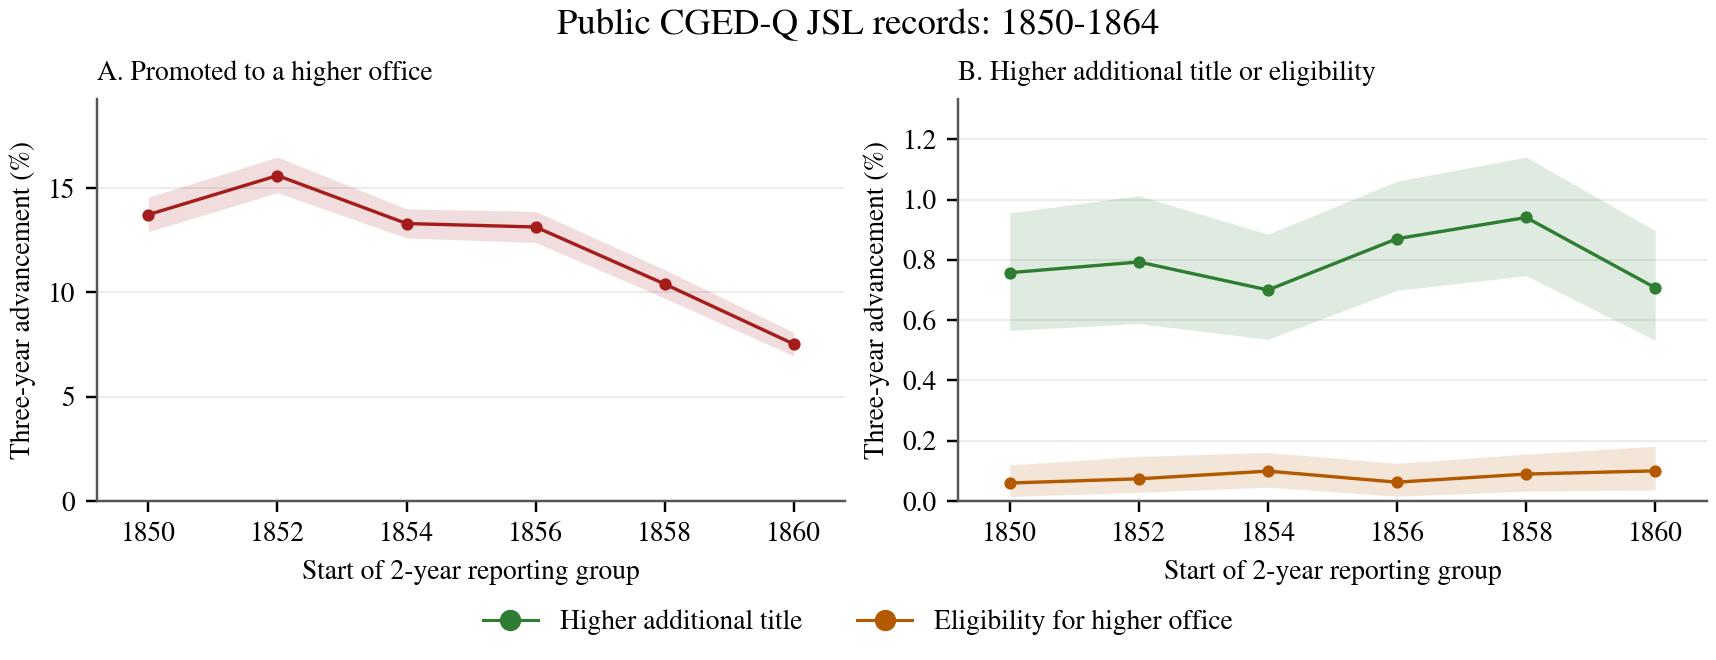

In [7]:
mobility.plot_rates(group_rates, OUTPUT, REPORT_YEARS)
display(Image(data=(OUTPUT / "component_mobility.png").read_bytes()))

Plotted percentages under the main `retained` rule:

In [8]:
plot_values = group_rates.loc[
    group_rates.rule.eq("retained") & group_rates.outcome.isin(labels),
    ["period", "first_start_year", "last_start_year", "outcome", "pairs", "pct"],
].copy()
plot_values["outcome"] = plot_values.outcome.map(labels)
display(plot_values.pivot(index="period", columns="outcome", values="pct")
        .rename_axis(index="Reporting-group start", columns=None).round(3))

,Became eligible for a higher office,Promoted to a higher office,Received a higher additional title
Reporting-group start,,,
1850,0.059,13.723,0.757
1852,0.073,15.595,0.793
1854,0.099,13.295,0.700
1856,0.062,13.130,0.870
1858,0.089,10.396,0.941
1860,0.100,7.518,0.707


## 6. Save the results

Save rates, annual coverage, an initial-years sensitivity check, provenance, and figures under `private/`. Rerunning updates these outputs.

In [9]:
coverage = (
    records.groupby(["window", "year"], observed=True)
    .agg(records=("person_id", "size"), officials=("person_id", "nunique"))
    .join(pairs.groupby(["window", "year"], observed=True).size()
          .rename("three_year_pairs"), how="left")
    .fillna(0).reset_index()
)
audit.update({
    "entry_point": "examples/public_mobility.ipynb",
    "analysis_code_sha256": mobility.sha256(ROOT / "examples/public_mobility.py"),
    "python": platform.python_version(),
    "dependencies": {name: importlib.metadata.version(name)
                     for name in ["numpy", "pandas", "scipy", "matplotlib", "requests"]},
    "person_years": len(annual),
    "office_ranked_person_years": len(ranked),
    "three_year_pairs": len(pairs),
    "pair_officials": int(pairs.person_id.nunique()),
    "gap_years": mobility.GAP,
    "reporting_group_years": REPORT_YEARS,
    "reporting_group_anchor": "first year of each selected public window",
    "draws": BOOTSTRAP_DRAWS,
    "seed": SEED,
    "start_year_filter": START_YEAR,
    "end_year_filter": END_YEAR,
    "component_history_resets_at_window_boundaries": True,
    "observed_record_years": {
        str(w): sorted(g.year.unique().tolist())
        for w, g in records.groupby("window", observed=True)
    },
    "observed_pair_start_years": {
        str(w): sorted(g.year.unique().tolist())
        for w, g in pairs.groupby("window", observed=True)
    },
    "dataverse_files": download_manifest,
    "not_an_exact_manuscript_replication": True,
})
window_rates.to_csv(OUTPUT / "window_rates.csv", index=False)
group_rates.to_csv(OUTPUT / "reporting_group_rates.csv", index=False)
coverage.to_csv(OUTPUT / "annual_coverage.csv", index=False)
mobility.initial_year_sensitivity(pairs).to_csv(
    OUTPUT / "initial_year_sensitivity.csv", index=False
)
(OUTPUT / "provenance.json").write_text(
    json.dumps(audit, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
print("Saved aggregate CSVs, provenance, and the PNG/PDF figure under "
      + str(OUTPUT.relative_to(ROOT)) + "/.")

Saved aggregate CSVs, provenance, and the PNG/PDF figure under private/public_mobility/notebook_1850_1864_2y/.


## Reading these results

These rates describe officials observed with ranked offices three years apart. The 1850–1864 records allow comparison starts through 1861. The paper uses a longer period and five-year reporting groups.

See [method details](../docs/public_mobility.md). When using this example, cite the [paper](https://osf.io/preprints/socarxiv/eg87f_v1) and [CGED-Q](https://doi.org/10.7910/DVN/GMQWVZ).